# 06. Association Rules, Categorical Association Tests and Correspondence Analysis

**Questions.** Which *combinations* of early behaviour and background go together with ending the course at risk (RQ1), and where do equity gaps appear (RQ4)?

**Design rules**

- **Everything here is mined on the 2013 training years only.** The 2014 results are not touched. The selected rules and the item definitions are saved so that notebook 07 can test whether the rules *replicate* in 2014 (a temporal replication, run once).
- **Items come from one shared definition** (`src/items.py`): each student gets one categorical value per variable (engagement profile from notebook 05, education, deprivation, age, disability, gender, prior attempts, module, credit load, early assessment behaviour, early score tertile, submission timing, forum use). Rare levels are merged only here and the merges are documented below.
- **Outcome items** are kept out of the antecedents: *At risk*, *Not at risk*, and the four results (Distinction, Pass, Fail, Withdrawn).
- **Thousands of rules means thousands of chances for false positives**, so every rule carries a confidence interval, a p-value corrected for multiple testing (Benjamini-Hochberg), and is dropped when it adds nothing over a simpler rule it contains.
- Statistics follow the variable type: chi-square with Cramer's V for nominal variables, a linear-by-linear trend test for ordered variables, a stratified (Cochran-Mantel-Haenszel) test when a third variable could confound.

In [1]:
import sys, json, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import StratifiedTable, Table2x2
from mlxtend.frequent_patterns import fpgrowth, association_rules

sys.path.insert(0, "../src")
import items as it

RANDOM_STATE = 42
PROC, OUT = Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
KEY = it.KEY

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C1, C2 = "#2a78d6", "#eb6834"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
def savefig(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

feat = pd.read_csv(PROC / "oulad_features_day28.csv")
clus = pd.read_csv(PROC / "oulad_clusters_day28.csv")
train = feat[feat.split == "train"].reset_index(drop=True)
spec = it.fit_item_spec(train)
cats = it.categories(train, clus, spec)
items = it.to_items(cats)
outc = it.outcome_items(train)
basket = pd.concat([items, outc], axis=1)
N = len(basket)
base_rate = outc["Outcome=AtRisk"].mean()
print(f"{N:,} training students | {items.shape[1]} predictor items + {outc.shape[1]} outcome items | base at-risk rate {base_rate:.3f}")
print("item spec (fitted on the training years):", spec)

11,818 training students | 35 predictor items + 6 outcome items | base at-risk rate 0.444
item spec (fitted on the training years): {'score_tertile_cuts': [0.3371369953894442, 0.6492652745552978], 'forum_rank_cut': 0.667, 'early_days_cut': 7, 'light_credits': 60, 'medium_credits': 120}


## 1. Items

In [2]:
sup = items.mean().sort_values(ascending=False)
print("Most and least frequent predictor items (share of students):")
display(pd.concat([sup.head(8), sup.tail(8)]).to_frame("support"))
print("Merges made for the rules (documented): Education = BelowALevel (no formal + lower than A level), ALevel, HEplus (HE + postgraduate); Age = Under35 vs 35plus (35-55 and 55+); Deprivation = Deprived (bands 1-3), Middle (4-7), Affluent (8-10), Unknown.")
print("\nMissing by design (not items): early score and timing only exist for students who submitted; forum use only for active students.")
print({v: int(cats[v].isna().sum()) for v in ["EarlyScore", "Timing", "Forum"]})

Most and least frequent predictor items (share of students):


,support
EarlyAssessment=SubmittedAll,0.720
Age=Under35,0.697
Load=Light,0.641
Timing=Deadline,0.622
Gender=M,0.518
Gender=F,0.482
Education=ALevel,0.433
Education=BelowALevel,0.420
Timing=Early,0.112
Disability=Yes,0.095


Merges made for the rules (documented): Education = BelowALevel (no formal + lower than A level), ALevel, HEplus (HE + postgraduate); Age = Under35 vs 35plus (35-55 and 55+); Deprivation = Deprived (bands 1-3), Middle (4-7), Affluent (8-10), Unknown.

Missing by design (not items): early score and timing only exist for students who submitted; forum use only for active students.
{'EarlyScore': 3178, 'Timing': 3137, 'Forum': 457}


**Observed.** The 11,818 training students form baskets of 35 predictor items plus the outcome items. The most frequent items are `EarlyAssessment=SubmittedAll` (72%), `Age=Under35` (70%) and `Load=Light` (64%); the rarest include `Profile=NoActivity` (3.9%, 457 students) and `Disability=Yes` (9.5%).
Early score, submission timing and forum use are missing by design for 3,178, 3,137 and 457 students (nobody scored, nobody submitted, nobody active), so those students simply carry no item for that variable.

## 2. Categorical association with the outcome

### 2.1 Chi-square, effect size (Cramer's V) and a bootstrap interval

,n,levels,cramers_v,v_lo,v_hi,v_vs_4_results,p_adj_BH,min_expected_count
variable,,,,,,,,
EarlyAssessment,11818,3,0.327,0.312,0.343,0.241,0.000,649.672
Profile,11818,4,0.310,0.295,0.322,0.193,0.000,202.939
EarlyScore,8640,3,0.302,0.285,0.321,0.256,0.000,"1,132.681"
EducationFine,11818,5,0.166,0.148,0.184,0.105,0.000,38.634
Deprivation,11818,4,0.146,0.127,0.166,0.089,0.000,185.621
IMDBand,11400,10,0.146,0.126,0.164,0.091,0.000,431.100
PriorAttempts,11818,2,0.132,0.111,0.150,0.137,0.000,716.282
Module,11818,6,0.125,0.111,0.145,0.106,0.000,164.305
Timing,8681,2,0.095,0.074,0.113,0.121,0.000,525.360


variables whose smallest expected cell count is below 5 (chi-square assumption at risk): []


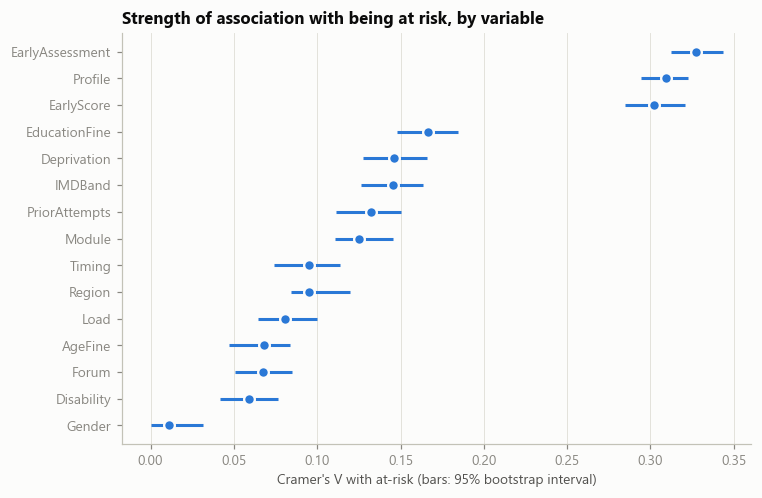

In [3]:
def cramers_v(ct):
    ct = np.asarray(ct, float); n = ct.sum(); r, c = ct.shape
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    phi2 = max(0, chi2 / n - (c - 1) * (r - 1) / (n - 1)); rc, cc = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(cc - 1, rc - 1))))

TEST_VARS = ["Profile", "EducationFine", "IMDBand", "Deprivation", "AgeFine", "Disability", "Gender", "PriorAttempts", "Module", "Region",
             "Load", "EarlyAssessment", "EarlyScore", "Timing", "Forum"]
d = cats.assign(AtRisk=train.target_at_risk.values, Result=train.target_final_result.values)
rng = np.random.RandomState(RANDOM_STATE)
rows = []
for v in TEST_VARS:
    sub = d[[v, "AtRisk", "Result"]].dropna()
    ct = pd.crosstab(sub[v], sub.AtRisk); chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    boots = []
    for _ in range(200):
        s = sub.iloc[rng.randint(0, len(sub), len(sub))]
        boots.append(cramers_v(pd.crosstab(s[v], s.AtRisk)))
    rows.append(dict(variable=v, n=len(sub), levels=ct.shape[0], chi2=chi2, p=p, cramers_v=cramers_v(ct), v_lo=np.percentile(boots, 2.5), v_hi=np.percentile(boots, 97.5),
                     v_vs_4_results=cramers_v(pd.crosstab(sub[v], sub.Result)), min_expected_count=exp.min()))
chi = pd.DataFrame(rows).set_index("variable")
chi["p_adj_BH"] = multipletests(chi.p, method="fdr_bh")[1]
chi = chi.sort_values("cramers_v", ascending=False)
chi.to_csv(OUT / "chi_square_effects.csv")
display(chi[["n", "levels", "cramers_v", "v_lo", "v_hi", "v_vs_4_results", "p_adj_BH", "min_expected_count"]])
print("variables whose smallest expected cell count is below 5 (chi-square assumption at risk):", list(chi.index[chi.min_expected_count < 5]))

top = chi.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.hlines(top.index, top.v_lo, top.v_hi, color=C1, linewidth=2); ax.plot(top.cramers_v, top.index, "o", color=C1, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.set_xlabel("Cramer's V with at-risk (bars: 95% bootstrap interval)"); ax.grid(axis="y", visible=False); ax.set_title("Strength of association with being at risk, by variable")
fig.tight_layout(); savefig(fig, "06_cramers_v.png"); plt.show()

**Observed.** Behaviour in the first four weeks is the most strongly associated with the outcome: early assessment behaviour (Cramer's V 0.33, 95% interval 0.31 to 0.34), engagement profile (0.31) and early score (0.30). Background comes next: prior education (0.17), deprivation (0.15), prior attempts (0.13) and module (0.13). Weaker: submission timing and region (0.10), credit load (0.08), age and forum use (0.07), disability (0.06). **Gender has no association** (V 0.011, interval including 0, corrected p 0.12).
**Why it matters.** With almost 12,000 students nearly every test is significant after correction, so the p-value cannot rank anything. The effect size can: behaviour is about twice as strongly associated as any background variable. All expected cell counts are at least 33, so the chi-square assumption holds.
**Action.** Gender is left out of the conclusions. Region (13 levels, V 0.10) is not used for rules.

### 2.2 Trend tests for ordered variables (linear-by-linear association)

For an ordered variable a general chi-square wastes the ordering. The trend statistic is M2 = (n - 1) r2 with r the correlation between the level scores and the outcome, tested against chi-square with 1 degree of freedom.

In [4]:
ORDER = {"EducationFine": ["NoFormal", "BelowALevel", "ALevel", "HE", "PostGrad"], "IMDBand": [f"B{i:02d}" for i in range(1, 11)],
         "Load": ["Light", "Medium", "Heavy"], "PriorAttempts": ["0", "1plus"], "EarlyScore": ["Low", "Mid", "High"],
         "Profile": ["NoActivity", "Low", "Intermittent", "Sustained"]}
rows = []
for v, lv in ORDER.items():
    sub = d[[v, "AtRisk"]].dropna(); sub = sub[sub[v].isin(lv)]
    score = sub[v].map({l: i for i, l in enumerate(lv)}).astype(float)
    r = np.corrcoef(score, sub.AtRisk)[0, 1]; m2 = (len(sub) - 1) * r ** 2
    rows.append(dict(variable=v, levels=len(lv), direction="higher level, more at risk" if r > 0 else "higher level, less at risk", r=r, M2=m2, p=stats.chi2.sf(m2, 1)))
trend = pd.DataFrame(rows).set_index("variable"); trend["p_adj_BH"] = multipletests(trend.p, method="fdr_bh")[1]
trend

,levels,direction,r,M2,p,p_adj_BH
variable,,,,,,
EducationFine,5,"higher level, less at risk",-0.155,285.273,0.000,0.000
IMDBand,10,"higher level, less at risk",-0.142,230.072,0.000,0.000
Load,3,"higher level, more at risk",0.082,78.686,0.000,0.000
PriorAttempts,2,"higher level, more at risk",0.132,206.868,0.000,0.000
EarlyScore,3,"higher level, less at risk",-0.297,759.723,0.000,0.000
Profile,4,"higher level, less at risk",-0.310,"1,134.414",0.000,0.000


**Observed.** Every ordered variable shows a clear monotone trend. In the direction of lower risk: stronger engagement profile (r = -0.31, M2 = 1,134), higher early score (-0.30), more prior education (-0.16) and lower deprivation (-0.14). In the direction of higher risk: more previous attempts (+0.13) and a heavier credit load (+0.08).
**Why it matters.** The trend test uses the ordering, so it is more powerful than a plain chi-square and also says which way the gradient runs.

### 2.3 Is the association a confounding artefact? Stratified test (Cochran-Mantel-Haenszel)

Modules differ in both student mix and at-risk rate, so a crude odds ratio could mislead. The Mantel-Haenszel common odds ratio compares the groups *within* each module and pools the result; the Breslow-Day test asks whether the odds ratio is the same in every module.

In [5]:
def stratified(var, exposed, ref, strata="Module"):
    tabs, crude = [], np.zeros((2, 2))
    for m, g in d.groupby(strata):
        g = g[g[var].isin([exposed, ref])]
        t = np.array([[((g[var] == exposed) & (g.AtRisk == 1)).sum(), ((g[var] == exposed) & (g.AtRisk == 0)).sum()],
                      [((g[var] == ref) & (g.AtRisk == 1)).sum(), ((g[var] == ref) & (g.AtRisk == 0)).sum()]]) + 0.0
        if (t.sum(axis=1) > 0).all() and (t.sum(axis=0) > 0).all(): tabs.append(t); crude += t
    st = StratifiedTable(tabs); lo, hi = st.oddsratio_pooled_confint()
    c = Table2x2(crude)
    return dict(comparison=f"{var}: {exposed} vs {ref}", strata=len(tabs), crude_OR=c.oddsratio, pooled_MH_OR=st.oddsratio_pooled, MH_lo=lo, MH_hi=hi,
                MH_p=st.test_null_odds().pvalue, breslow_day_p=st.test_equal_odds().pvalue)
cmh = pd.DataFrame([stratified("Deprivation", "Deprived", "Affluent"), stratified("Disability", "Yes", "No"),
                    stratified("Education", "BelowALevel", "HEplus") if "Education" in d else stratified("EducationFine", "BelowALevel", "HE"),
                    stratified("PriorAttempts", "1plus", "0"), stratified("Gender", "M", "F"), stratified("Profile", "Low", "Sustained")]).set_index("comparison")
cmh

,strata,crude_OR,pooled_MH_OR,MH_lo,MH_hi,MH_p,breslow_day_p
comparison,,,,,,,
Deprivation: Deprived vs Affluent,6,1.989,1.999,1.809,2.210,0.000,0.311
Disability: Yes vs No,6,1.504,1.470,1.298,1.665,0.000,0.057
Education: BelowALevel vs HEplus,6,2.152,2.250,2.001,2.530,0.000,0.136
PriorAttempts: 1plus vs 0,3,1.976,1.974,1.769,2.203,0.000,0.483
Gender: M vs F,6,1.059,1.069,0.974,1.173,0.160,0.541
Profile: Low vs Sustained,6,4.165,4.109,3.724,4.533,0.000,0.000


In [6]:
# The engagement effect is not the same in every module (Breslow-Day test above): odds ratio of Low vs Sustained engagement, module by module
rows = []
for m, g in d.groupby("Module"):
    g = g[g.Profile.isin(["Low", "Sustained"])]
    t = np.array([[((g.Profile == "Low") & (g.AtRisk == 1)).sum(), ((g.Profile == "Low") & (g.AtRisk == 0)).sum()],
                  [((g.Profile == "Sustained") & (g.AtRisk == 1)).sum(), ((g.Profile == "Sustained") & (g.AtRisk == 0)).sum()]]) + 0.0
    T = Table2x2(t); lo_, hi_ = T.oddsratio_confint()
    rows.append(dict(module=m, n=int(t.sum()), rate_low=t[0, 0] / t[0].sum(), rate_sustained=t[1, 0] / t[1].sum(), odds_ratio=T.oddsratio, ci_low=lo_, ci_high=hi_))
by_module_or = pd.DataFrame(rows).set_index("module"); by_module_or

,n,rate_low,rate_sustained,odds_ratio,ci_low,ci_high
module,,,,,,
AAA,268,0.339,0.176,2.404,1.361,4.247
BBB,2128,0.586,0.279,3.655,3.035,4.401
DDD,1970,0.728,0.354,4.881,4.002,5.953
EEE,499,0.681,0.154,11.708,6.986,19.619
FFF,2365,0.659,0.287,4.805,4.026,5.733
GGG,616,0.407,0.299,1.613,1.143,2.275


**Observed.** The background effects are **not** artefacts of the module mix. The Mantel-Haenszel odds ratio, which compares students within the same module, is almost identical to the crude one: deprived vs affluent 1.99 crude and 2.00 pooled (95% interval 1.81 to 2.21), education below A level vs higher education 2.15 and 2.25, disability 1.50 and 1.47, prior attempts 1.98 and 1.97. The Breslow-Day tests find the same odds ratio in every module (p of 0.14 to 0.54; disability, at 0.057, is borderline). Gender stays null (1.07, interval 0.97 to 1.17).
**The engagement effect is different.** The pooled odds ratio of low vs sustained engagement (4.1) hides large module differences (Breslow-Day p below 0.001): from 11.7 in EEE (95% interval 7.0 to 19.6), 4.9 in DDD and 4.8 in FFF, down to 2.4 in AAA and only 1.6 in GGG (1.1 to 2.3).
**Why it matters.** Early engagement is a strong warning sign in some modules and a weak one in others, which matches notebook 04 (GGG is the hardest module to predict). A pooled statement hides this.
**Action.** Report engagement effects per module, and test a module interaction in notebook 07.

## 3. Association rules (FP-growth)

### 3.1 Frequent itemsets and candidate rules

In [7]:
MIN_SUP, MAX_LEN = 0.02, 4
OUT_SET = set(it.OUTCOME_ITEMS)
freq = fpgrowth(basket, min_support=MIN_SUP, use_colnames=True, max_len=MAX_LEN)
n_out = freq.itemsets.apply(lambda s: len(s & OUT_SET))
freq = freq[n_out <= 1].reset_index(drop=True)      # keep itemsets with at most one outcome item (closed under taking subsets)
print(f"{len(freq):,} frequent itemsets at support >= {MIN_SUP} (>= {int(MIN_SUP * N)} students), max length {MAX_LEN}")
raw_rules = association_rules(freq, metric="confidence", min_threshold=0.0)
ok = raw_rules.consequents.apply(lambda s: len(s) == 1 and next(iter(s)) in OUT_SET) & raw_rules.antecedents.apply(lambda s: not (s & OUT_SET))
R = raw_rules[ok].copy().reset_index(drop=True)
R["consequent"] = R.consequents.apply(lambda s: next(iter(s)))
R["n_antecedent"] = (R["antecedent support"] * N).round().astype(int)
R["n_rule"] = (R.support * N).round().astype(int)
R["len"] = R.antecedents.apply(len)
print(f"{len(R):,} candidate rules with an outcome item as the only consequent")

10,798 frequent itemsets at support >= 0.02 (>= 236 students), max length 4


5,123 candidate rules with an outcome item as the only consequent


In [8]:
# Uncertainty and multiple testing for every candidate rule
a = R.n_rule.values.astype(float); b = (R.n_antecedent - R.n_rule).values.astype(float)
n_c = (R["consequent support"] * N).round().values.astype(float)
c_ = n_c - a; d_ = N - a - b - c_
chi2_ = N * (a * d_ - b * c_) ** 2 / ((a + b) * (c_ + d_) * (a + c_) * (b + d_))
R["p"] = stats.chi2.sf(chi2_, 1)
R["q"] = multipletests(R.p.values, method="fdr_bh")[1]
lo, hi = proportion_confint(R.n_rule, R.n_antecedent, method="wilson"); R["conf_lo"], R["conf_hi"] = lo, hi
R["recall"] = R.support / R["consequent support"]          # share of the outcome group that the rule covers

# Redundancy: a longer rule must beat its best sub-rule by at least IMPROVE points of confidence
IMPROVE = 0.03
conf = {(r.antecedents, r.consequent): r.confidence for r in R.itertuples()}
csup = R.groupby("consequent")["consequent support"].first().to_dict()      # the outcome's overall rate = the confidence of the empty rule
def best_sub(r):
    A = tuple(r.antecedents); best = csup[r.consequent]
    for k in range(1, len(A)):
        for sub in itertools.combinations(A, k):
            best = max(best, conf.get((frozenset(sub), r.consequent), 0))
    return best
R["best_sub_conf"] = [best_sub(r) for r in R.itertuples()]
R["improvement"] = R.confidence - R.best_sub_conf
R["rule"] = R.antecedents.apply(lambda s: " AND ".join(sorted(s)))
print(f"rules significant after correction (q < 0.05): {(R.q < 0.05).sum():,} of {len(R):,}")
print("the same count among rules with lift above 1.2:", int(((R.q < 0.05) & (R.lift > 1.2)).sum()))

rules significant after correction (q < 0.05): 4,159 of 5,123
the same count among rules with lift above 1.2: 1631


**Observed.** FP-growth finds 10,798 frequent itemsets at 2% support (at least 236 students) and 5,123 candidate rules with an outcome as the consequent. After Benjamini-Hochberg correction 4,159 (81%) are "significant", and 1,631 still have a lift above 1.2.
**Why it matters.** At this sample size significance does not separate useful rules from noise, so the real filters are the lift, the confidence interval and the improvement over simpler rules. Requiring a lift of at least 1.25, at least 150 students, corrected p below 0.05 and an improvement of at least 3 points over every simpler rule leaves **173 rules**: 50 for at risk, 59 for not at risk, 24 for Fail, 12 for Withdrawn, 20 for Pass and 8 for Distinction.

### 3.2 Rules for being at risk

In [9]:
cols = ["rule", "n_antecedent", "support", "confidence", "conf_lo", "conf_hi", "lift", "recall", "q", "improvement"]
def top_rules(consequent, n=12, min_conf=None, min_lift=1.25, by="lift", min_n=150):
    t = R[(R.consequent == consequent) & (R.q < 0.05) & (R.lift >= min_lift) & (R.improvement >= IMPROVE) & (R.n_antecedent >= min_n)]
    if min_conf: t = t[t.confidence >= min_conf]
    return t.sort_values(by, ascending=False).head(n)[cols]
risk_rules = top_rules("Outcome=AtRisk", n=14)
print(f"base rate {base_rate:.3f}; rules sorted by lift, significant (q < 0.05), non-redundant, at least 150 students:")
display(risk_rules.reset_index(drop=True))

base rate 0.444; rules sorted by lift, significant (q < 0.05), non-redundant, at least 150 students:


,rule,n_antecedent,support,confidence,conf_lo,conf_hi,lift,recall,q,improvement
0,Deprivation=Deprived AND EarlyAssessment=MissedSome AND Education=BelowALevel,326,0.026,0.960,0.933,0.977,2.162,0.060,0.000,0.040
1,EarlyAssessment=MissedSome AND Profile=NoActivity,276,0.022,0.928,0.891,0.953,2.089,0.049,0.000,0.052
2,EarlyAssessment=MissedSome AND Education=BelowALevel,749,0.058,0.920,0.898,0.937,2.072,0.131,0.000,0.044
3,Deprivation=Deprived AND EarlyAssessment=MissedSome,573,0.044,0.909,0.883,0.930,2.048,0.099,0.000,0.034
4,EarlyAssessment=MissedSome,1463,0.108,0.876,0.858,0.892,1.972,0.244,0.000,0.432
5,Education=BelowALevel AND Module=DDD AND Profile=Low,289,0.020,0.834,0.787,0.872,1.878,0.046,0.000,0.106
6,Deprivation=Deprived AND Education=BelowALevel AND Profile=Low,493,0.034,0.811,0.774,0.843,1.827,0.076,0.000,0.085
7,Profile=NoActivity,457,0.031,0.807,0.769,0.841,1.818,0.070,0.000,0.363
8,EarlyScore=Low AND Education=BelowALevel AND Module=DDD,315,0.021,0.790,0.742,0.832,1.780,0.047,0.000,0.050
9,Deprivation=Deprived AND Module=FFF AND Profile=Low,323,0.021,0.783,0.735,0.825,1.764,0.048,0.000,0.067


In [10]:
prot_rules = top_rules("Outcome=NotAtRisk", n=10)
print("Protective rules (not at risk):"); display(prot_rules.reset_index(drop=True))
fail_rules = top_rules("Result=Fail", n=8); wd_rules = top_rules("Result=Withdrawn", n=8)
print("Rules for FAIL:"); display(fail_rules.reset_index(drop=True))
print("Rules for WITHDRAWN:"); display(wd_rules.reset_index(drop=True))

Protective rules (not at risk):


,rule,n_antecedent,support,confidence,conf_lo,conf_hi,lift,recall,q,improvement
0,EarlyScore=High AND Education=HEplus AND Profile=Sustained,311,0.023,0.878,0.837,0.910,1.579,0.042,0.000,0.052
1,EarlyAssessment=NoneDue AND Education=ALevel AND Profile=Sustained,296,0.021,0.848,0.803,0.884,1.525,0.038,0.000,0.073
2,Module=EEE AND Profile=Sustained,408,0.029,0.846,0.807,0.877,1.521,0.053,0.000,0.133
3,EarlyScore=High AND Timing=Early,451,0.032,0.843,0.806,0.873,1.516,0.058,0.000,0.082
4,EarlyScore=High AND Profile=Sustained,1656,0.116,0.825,0.806,0.843,1.485,0.208,0.000,0.064
5,Deprivation=Affluent AND EarlyScore=High AND Gender=F,388,0.027,0.820,0.778,0.855,1.474,0.048,0.000,0.033
6,EarlyScore=High AND Education=HEplus,546,0.038,0.817,0.782,0.847,1.469,0.068,0.000,0.056
7,EarlyScore=Mid AND Profile=Sustained AND Timing=Early,298,0.021,0.815,0.767,0.855,1.467,0.037,0.000,0.039
8,EarlyAssessment=NoneDue AND Gender=M AND Profile=Sustained,442,0.030,0.812,0.773,0.846,1.461,0.055,0.000,0.038
9,Deprivation=Affluent AND Load=Light AND Profile=Sustained,875,0.060,0.807,0.779,0.832,1.451,0.107,0.000,0.031


Rules for FAIL:


,rule,n_antecedent,support,confidence,conf_lo,conf_hi,lift,recall,q,improvement
0,Profile=NoActivity,457,0.023,0.602,0.556,0.646,2.199,0.085,0.000,0.328
1,EarlyAssessment=MissedSome AND Module=BBB,479,0.024,0.587,0.542,0.630,2.144,0.087,0.000,0.079
2,Deprivation=Deprived AND EarlyAssessment=MissedSome,573,0.027,0.564,0.523,0.604,2.060,0.100,0.000,0.057
3,EarlyAssessment=MissedSome AND Education=BelowALevel,749,0.035,0.553,0.517,0.588,2.020,0.128,0.000,0.046
4,Deprivation=Deprived AND Education=BelowALevel AND Profile=Low,493,0.023,0.548,0.504,0.591,2.001,0.083,0.000,0.079
5,EarlyAssessment=MissedSome AND Load=Light,826,0.038,0.546,0.512,0.580,1.995,0.139,0.000,0.039
6,Deprivation=Deprived AND Gender=M AND Profile=Low,485,0.022,0.526,0.481,0.570,1.921,0.079,0.000,0.057
7,EarlyAssessment=MissedSome,1463,0.063,0.507,0.482,0.533,1.853,0.229,0.000,0.234


Rules for WITHDRAWN:


,rule,n_antecedent,support,confidence,conf_lo,conf_hi,lift,recall,q,improvement
0,EarlyAssessment=MissedSome AND Module=DDD,598,0.022,0.430,0.391,0.470,2.522,0.128,0.000,0.061
1,EarlyAssessment=MissedSome,1463,0.046,0.368,0.344,0.393,2.162,0.268,0.000,0.198
2,EarlyScore=Low AND Module=DDD,770,0.022,0.343,0.310,0.377,2.012,0.131,0.000,0.103
3,Module=DDD AND Profile=Low,760,0.020,0.318,0.286,0.352,1.868,0.120,0.000,0.079
4,Load=Medium AND Module=DDD,913,0.023,0.291,0.263,0.322,1.710,0.132,0.000,0.052
5,Education=BelowALevel AND Module=DDD,1017,0.025,0.286,0.259,0.315,1.679,0.144,0.000,0.047
6,Education=BelowALevel AND Profile=Low,1250,0.028,0.268,0.244,0.293,1.573,0.166,0.000,0.036
7,Load=Medium AND Profile=Low,966,0.022,0.266,0.239,0.295,1.561,0.128,0.000,0.034


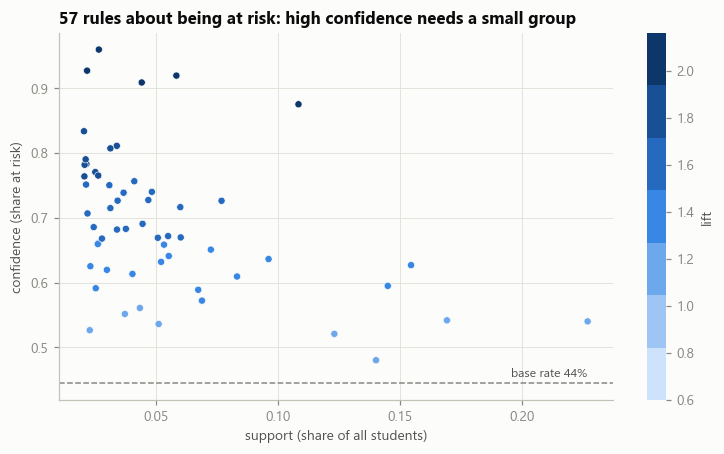

In [11]:
# Support, confidence and lift of all significant, non-redundant at-risk rules
S = R[(R.consequent == "Outcome=AtRisk") & (R.q < 0.05) & (R.improvement >= IMPROVE) & (R.n_antecedent >= 150)]
fig, ax = plt.subplots(figsize=(7, 4.2))
sc = ax.scatter(S.support, S.confidence, c=S.lift, cmap=plt.matplotlib.colors.ListedColormap(SEQ), s=22, edgecolors=SURFACE, linewidths=0.4, vmin=0.6, vmax=S.lift.max())
ax.axhline(base_rate, color=MUTED, linestyle="--", linewidth=1); ax.text(S.support.max(), base_rate + 0.01, f"base rate {base_rate:.0%}", ha="right", color=INK2, fontsize=8)
cb = fig.colorbar(sc, ax=ax); cb.set_label("lift"); cb.outline.set_visible(False)
ax.set_xlabel("support (share of all students)"); ax.set_ylabel("confidence (share at risk)"); ax.set_title(f"{len(S)} rules about being at risk: high confidence needs a small group")
fig.tight_layout(); savefig(fig, "06_rules_scatter.png"); plt.show()

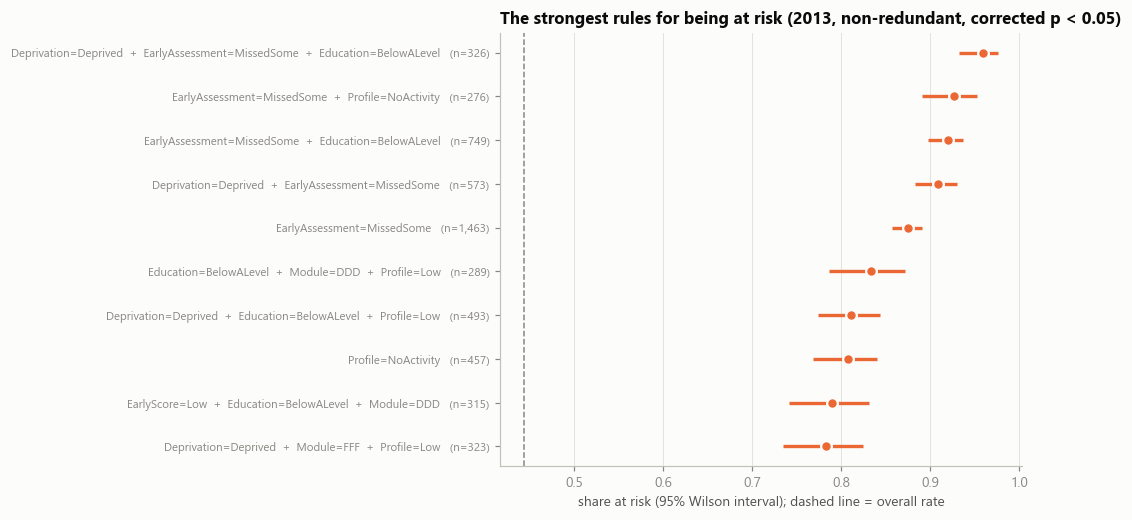

In [12]:
# Lollipop of the strongest at-risk rules with 95% intervals
t = risk_rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
y = np.arange(len(t))
ax.hlines(y, t.conf_lo, t.conf_hi, color=C2, linewidth=2.2); ax.plot(t.confidence, y, "o", color=C2, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axvline(base_rate, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y, [r.replace(" AND ", "  +  ") + f"   (n={n:,})" for r, n in zip(t.rule, t.n_antecedent)], fontsize=7.5)
ax.set_xlabel("share at risk (95% Wilson interval); dashed line = overall rate"); ax.grid(axis="y", visible=False)
ax.set_title("The strongest rules for being at risk (2013, non-redundant, corrected p < 0.05)")
fig.tight_layout(); savefig(fig, "06_top_risk_rules.png"); plt.show()

**Observed.** The strongest rule is also the simplest: **missing at least one assessment due before day 28** (`EarlyAssessment=MissedSome`) goes with 87.6% at risk (95% interval 85.8 to 89.2; 1,463 students, 12.4% of all; lift 1.97), and the rule alone covers 24.4% of all at-risk students. Adding a disadvantaged background raises the confidence a little more: with education below A level 92.0% (n = 749), with high deprivation 90.9% (n = 573), with both 96.0% (n = 326, interval 93.3 to 97.7). The maximum possible lift is 2.25 (1 divided by the 44.4% base rate), so these rules are close to certainty, but the last one covers only 6% of the at-risk students.
Engagement rules are weaker but broader: no activity 80.7% (n = 457), low engagement with education below A level in module DDD 83.4%.
The protective rules mirror these: sustained engagement with a high early score and higher education is 87.8% *not* at risk (n = 311), and sustained engagement with a high early score alone is 82.5% (n = 1,656).
**Fail and Withdrawn differ.** Fail rules lean on engagement and deprivation (no activity: 60.2% fail), while Withdrawn rules are tied to module DDD (missed assessment in DDD: 43.0% withdrawn, lift 2.5; low early score in DDD: 34.3%).
**Why it matters.** One behavioural fact (an early assessment not handed in) captures most of what any combination adds; background and module add a few points on top. The scatter plot shows the usual trade-off: confidence rises only for small groups.
**Caution.** All of this is association measured on 2013; notebook 07 tests whether the rules replicate in 2014.

### 3.3 From rules to a support list (business view)

A support team cannot contact everyone. Rules are added greedily by the number of *new* at-risk students they cover, while the precision of the combined list stays at or above 60%.

In [13]:
y_risk = outc["Outcome=AtRisk"].values
def greedy_list(floor, max_rules=8):
    cand = R[(R.consequent == "Outcome=AtRisk") & (R.q < 0.05) & (R.confidence >= floor) & (R.n_antecedent >= 150) & (R.improvement >= IMPROVE)]
    masks = {r.rule: basket[list(r.antecedents)].all(axis=1).values for r in cand.itertuples()}
    chosen, covered = [], np.zeros(N, bool)
    for _ in range(max_rules):
        best, gain_best = None, 0
        for name, m in masks.items():
            if name in chosen: continue
            new = covered | m
            gain = (y_risk & new).sum() - (y_risk & covered).sum()
            if y_risk[new].mean() >= floor and gain > gain_best: best, gain_best = name, gain
        if best is None: break
        chosen.append(best); covered |= masks[best]
    rows, run = [], np.zeros(N, bool)
    for name in chosen:
        run |= masks[name]
        rows.append(dict(precision_floor=floor, rule_added=name, students_flagged=int(run.sum()), share_of_students=run.mean(), precision=y_risk[run].mean(), share_of_at_risk_reached=(y_risk & run).sum() / y_risk.sum()))
    return chosen, pd.DataFrame(rows)
chosen70, list70 = greedy_list(0.70); chosen, list60 = greedy_list(0.60)
support_list = pd.concat([list70, list60], ignore_index=True); support_list.to_csv(OUT / "rules_support_list.csv", index=False)
display(support_list)

,precision_floor,rule_added,students_flagged,share_of_students,precision,share_of_at_risk_reached
0,0.700,EarlyAssessment=MissedSome,1463,0.124,0.876,0.244
1,0.700,Education=BelowALevel AND Profile=Low,2336,0.198,0.785,0.349
2,0.700,EarlyScore=Low AND Module=DDD,2946,0.249,0.767,0.430
3,0.700,Deprivation=Deprived AND EarlyScore=Low AND Education=BelowALevel,3254,0.275,0.754,0.467
4,0.700,Deprivation=Deprived AND Profile=Low,3600,0.305,0.733,0.502
5,0.700,Age=Under35 AND Education=BelowALevel AND PriorAttempts=1plus,3804,0.322,0.724,0.525
6,0.700,Profile=NoActivity,3977,0.337,0.720,0.545
7,0.700,PriorAttempts=1plus AND Profile=Low,4099,0.347,0.714,0.558
8,0.600,Profile=Low,2914,0.247,0.627,0.348
9,0.600,Deprivation=Deprived AND Education=BelowALevel,4206,0.356,0.609,0.488


**Observed.** Two support lists, with rules added by the number of new at-risk students they reach while the precision of the combined list stays above a floor. At a **70% floor**, eight rules flag 34.7% of the students at 71.4% precision and reach 55.8% of the at-risk students; the first rule (missed assessment) flags 12.4% at 87.6% precision and reaches 24.4%, and adding "education below A level and low engagement" brings it to 19.8%, 78.5% and 34.9%. At a **60% floor** the list flags 55.0% of the students and reaches 75.1% of the at-risk ones at 60.7% precision.
**Why it matters.** There is no free lunch: every extra rule reaches fewer at-risk students at lower precision, and no rule list reaches most at-risk students without contacting half of the cohort. A sensible use is a priority order: (1) missed an early assessment, (2) no activity or low engagement with a vulnerable background, (3) wider outreach as capacity allows.

### 3.4 Equity lens: sensitive attributes in the rules

In [14]:
sens = R[(R.consequent == "Outcome=AtRisk") & (R.q < 0.05) & (R.n_antecedent >= 150) & (R.improvement >= IMPROVE) & R.antecedents.apply(lambda s: bool(s & set(it.SENSITIVE_ITEMS)) and len(s) == 2)]
print("Two-item at-risk rules containing a sensitive item that add at least 3 points over the simpler rule, strongest first:")
display(sens.sort_values("lift", ascending=False).head(10)[cols].reset_index(drop=True))

# Same behaviour, different circumstances: at-risk rate by deprivation within each profile and early-assessment group
for v in ("Profile", "EarlyAssessment"):
    piv = d[d.Deprivation != "Unknown"].pivot_table(index=v, columns="Deprivation", values="AtRisk", aggfunc=["mean", "size"], observed=True)
    out = pd.DataFrame({"Deprived": piv[("mean", "Deprived")], "Middle": piv[("mean", "Middle")], "Affluent": piv[("mean", "Affluent")],
                        "gap (Deprived - Affluent)": piv[("mean", "Deprived")] - piv[("mean", "Affluent")], "n Deprived": piv[("size", "Deprived")], "n Affluent": piv[("size", "Affluent")]})
    print(f"\nAt-risk rate by deprivation within {v}:"); display(out)

Two-item at-risk rules containing a sensitive item that add at least 3 points over the simpler rule, strongest first:


,rule,n_antecedent,support,confidence,conf_lo,conf_hi,lift,recall,q,improvement
0,EarlyAssessment=MissedSome AND Education=BelowALevel,749,0.058,0.920,0.898,0.937,2.072,0.131,0.000,0.044
1,Deprivation=Deprived AND EarlyAssessment=MissedSome,573,0.044,0.909,0.883,0.930,2.048,0.099,0.000,0.034
2,Education=BelowALevel AND Profile=Low,1250,0.077,0.726,0.701,0.750,1.636,0.173,0.000,0.099
3,Deprivation=Deprived AND Profile=Low,988,0.060,0.717,0.688,0.744,1.614,0.135,0.000,0.090
4,Education=BelowALevel AND PriorAttempts=1plus,760,0.044,0.691,0.657,0.723,1.556,0.100,0.000,0.081
5,Deprivation=Deprived AND PriorAttempts=1plus,588,0.034,0.682,0.643,0.718,1.536,0.076,0.000,0.073
6,Deprivation=Deprived AND EarlyScore=Low,1060,0.060,0.670,0.641,0.697,1.508,0.135,0.000,0.075
7,EarlyScore=Low AND Education=BelowALevel,1315,0.072,0.651,0.625,0.676,1.466,0.163,0.000,0.056
8,Education=BelowALevel AND Module=DDD,1017,0.055,0.641,0.611,0.670,1.444,0.124,0.000,0.101
9,Deprivation=Deprived AND Education=BelowALevel,1785,0.096,0.636,0.614,0.658,1.433,0.216,0.000,0.095



At-risk rate by deprivation within Profile:


,Deprived,Middle,Affluent,gap (Deprived - Affluent),n Deprived,n Affluent
Profile,,,,,,
Intermittent,0.545,0.452,0.415,0.131,1086,924
Low,0.717,0.602,0.560,0.157,988,686
NoActivity,0.839,0.778,0.769,0.070,205,78
Sustained,0.374,0.276,0.224,0.150,1415,1333



At-risk rate by deprivation within EarlyAssessment:


,Deprived,Middle,Affluent,gap (Deprived - Affluent),n Deprived,n Affluent
EarlyAssessment,,,,,,
MissedSome,0.909,0.870,0.855,0.054,573,290
NoneDue,0.439,0.344,0.278,0.161,558,492
SubmittedAll,0.482,0.372,0.331,0.151,2563,2239


**Observed.** Background appears in the rules mainly in combination with behaviour: education below A level and low engagement 72.6% at risk (n = 1,250), deprived and low engagement 71.7%, education below A level and a previous attempt 69.1%. Once the redundancy filter is applied the gender rules disappear: they added nothing to the rule they contained.
**The deprivation gap depends on behaviour.** Within each engagement profile the gap between the most and the least deprived students is 13 to 16 points (low engagement 71.7% vs 56.0%, sustained 37.4% vs 22.4%), and within early assessment groups it is 15 to 16 points for students who submitted everything (48.2% vs 33.1%) or had nothing due (43.9% vs 27.8%). **But among students who already missed an assessment it is only 5 points (90.9% vs 85.5%)**, and for students with no activity 7 points.
**Why it matters.** Once a student has missed an early assessment the risk is already about 90% whatever their background. Background matters most for students who still look fine on the platform: a disadvantaged student who submits on time is 15 points more likely to end up at risk than an affluent student who behaves the same way. An alert system based on behaviour alone would therefore miss exactly these students.
**Action.** Carry this into the fairness analysis of notebook 07, and report group-wise error rates for the deprived and low-education groups.

## 4. Correspondence analysis

Correspondence analysis (CA) shows a contingency table as a map. Rows and columns with similar profiles sit close together, and the distance from the centre shows how unusual a profile is. It is computed here directly from the singular value decomposition of the standardised residuals, and checked against the chi-square statistic (total inertia = chi-square / n).

In [15]:
def ca(table):
    Nn = table.values.astype(float); n = Nn.sum(); P = Nn / n; r = P.sum(1); c = P.sum(0)
    S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, sv, Vt = np.linalg.svd(S, full_matrices=False); k = min(Nn.shape) - 1
    U, sv, V = U[:, :k], sv[:k], Vt.T[:, :k]
    F = (U / np.sqrt(r)[:, None]) * sv; G = (V / np.sqrt(c)[:, None]) * sv
    inertia = sv ** 2
    chi2 = stats.chi2_contingency(Nn, correction=False)[0]
    assert np.isclose(inertia.sum(), chi2 / n, rtol=1e-6), "total inertia must equal chi-square / n"
    dims = [f"Dim{i + 1}" for i in range(k)]
    return dict(rows=pd.DataFrame(F, index=table.index, columns=dims), cols=pd.DataFrame(G, index=table.columns, columns=dims), inertia=inertia, share=inertia / inertia.sum(),
                total_inertia=inertia.sum(), chi2=chi2, n=n, row_contrib=pd.DataFrame(r[:, None] * F ** 2 / inertia, index=table.index, columns=dims),
                col_contrib=pd.DataFrame(c[:, None] * G ** 2 / inertia, index=table.columns, columns=dims))

def ca_plot(res, title, fname, row_label, col_label):
    fig, ax = plt.subplots(figsize=(6.8, 5.2))
    R_, C_ = res["rows"], res["cols"]
    ax.axhline(0, color=AXIS, linewidth=1); ax.axvline(0, color=AXIS, linewidth=1)
    ax.scatter(R_.Dim1, R_.Dim2, color=C1, s=36, zorder=3, edgecolors=SURFACE, linewidths=1)
    ax.scatter(C_.Dim1, C_.Dim2, color=C2, s=60, marker="D", zorder=3, edgecolors=SURFACE, linewidths=1)
    for lab, row in R_.iterrows(): ax.annotate(str(lab), (row.Dim1, row.Dim2), xytext=(5, 4), textcoords="offset points", color=C1, fontsize=8, fontweight="bold")
    for lab, row in C_.iterrows(): ax.annotate(str(lab), (row.Dim1, row.Dim2), xytext=(6, -10), textcoords="offset points", color=C2, fontsize=9, fontweight="bold")
    ax.set_xlabel(f"Dimension 1 ({res['share'][0]:.1%} of inertia)"); ax.set_ylabel(f"Dimension 2 ({res['share'][1]:.1%} of inertia)")
    ax.set_title(title); ax.text(0.01, 0.01, f"blue circles: {row_label}   orange diamonds: {col_label}", transform=ax.transAxes, fontsize=8, color=INK2)
    fig.tight_layout(); savefig(fig, fname); plt.show()

RESULTS = ["Distinction", "Pass", "Fail", "Withdrawn"]
d["Result4"] = train.target_final_result.values
tabs = {"IMDBand": pd.crosstab(d.IMDBand, d.Result4)[RESULTS], "Profile": pd.crosstab(d.Profile, d.Result4).loc[["NoActivity", "Low", "Intermittent", "Sustained"], RESULTS],
        "EducationFine": pd.crosstab(d.EducationFine, d.Result4).loc[ORDER["EducationFine"], RESULTS]}
ca_res = {k: ca(t) for k, t in tabs.items()}
summ = pd.DataFrame({k: {"n": int(r["n"]), "chi2": r["chi2"], "total_inertia": r["total_inertia"], "dim1_share": r["share"][0], "dim2_share": r["share"][1]} for k, r in ca_res.items()}).T
display(summ)

,n,chi2,total_inertia,dim1_share,dim2_share
IMDBand,"11,400.000",307.690,0.027,0.914,0.056
Profile,"11,818.000","1,323.170",0.112,0.959,0.031
EducationFine,"11,818.000",405.586,0.034,0.961,0.037


Deprivation bands x four results: coordinates


,band Dim1,band Dim2,contrib Dim1
IMDBand,,,
B01,-0.305,-0.029,0.385
B02,-0.176,-0.014,0.137
B03,-0.110,0.082,0.055
B04,-0.002,-0.008,0.000
B05,0.013,-0.030,0.001
B06,0.047,-0.042,0.009
B07,0.125,0.051,0.058
B08,0.102,0.024,0.040
B09,0.172,-0.013,0.103


,Dim1,Dim2
Result4,,
Distinction,0.274,-0.070
Pass,0.106,0.016
Fail,-0.194,-0.038
Withdrawn,-0.114,0.057


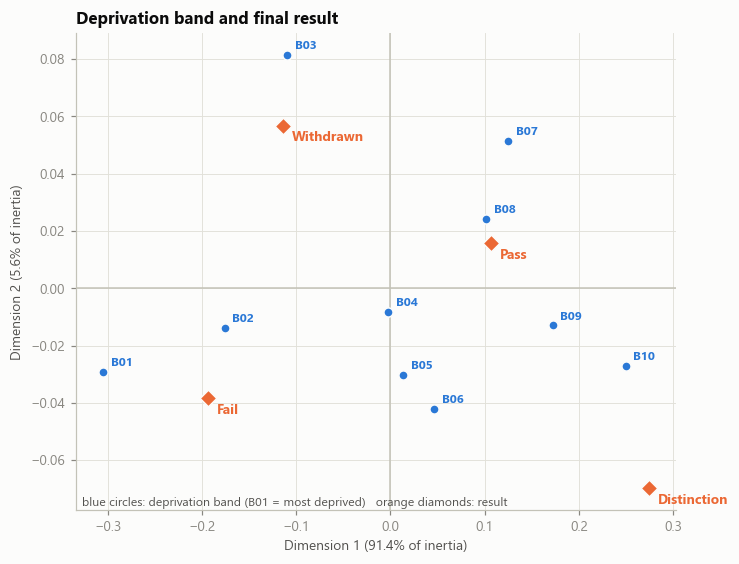

In [16]:
r_ = ca_res["IMDBand"]
print("Deprivation bands x four results: coordinates"); display(pd.concat([r_["rows"][["Dim1", "Dim2"]].add_prefix("band "), r_["row_contrib"][["Dim1"]].add_prefix("contrib ")], axis=1))
display(r_["cols"][["Dim1", "Dim2"]])
ca_plot(r_, "Deprivation band and final result", "06_ca_imd_result.png", "deprivation band (B01 = most deprived)", "result")

Engagement profile x four results: coordinates


,Dim1,Dim2
Profile,,
NoActivity,-0.764,0.230
Low,-0.378,-0.015
Intermittent,-0.064,-0.059
Sustained,0.340,0.030


,Dim1,Dim2
Result4,,
Distinction,0.546,0.141
Pass,0.224,-0.036
Fail,-0.418,0.047
Withdrawn,-0.232,-0.053


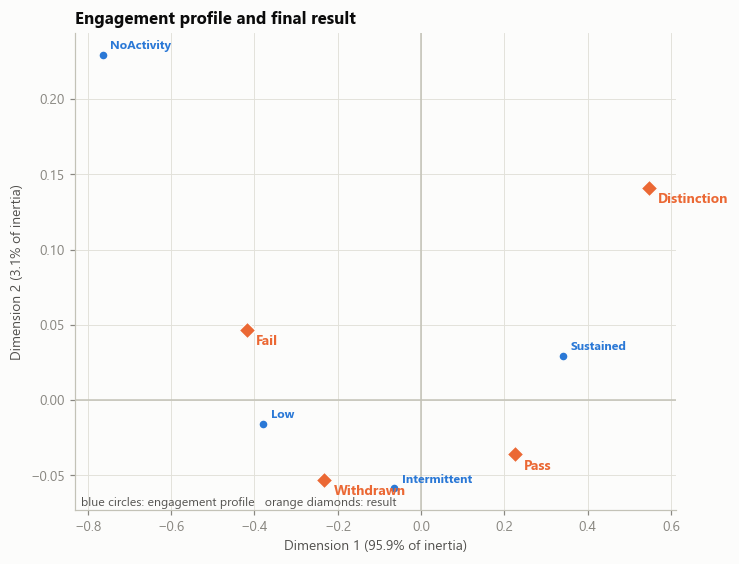

Prior education x four results: coordinates


,Dim1,Dim2
EducationFine,,
NoFormal,-0.371,-0.134
BelowALevel,-0.203,-0.004
ALevel,0.127,0.022
HE,0.204,-0.031
PostGrad,0.504,-0.317


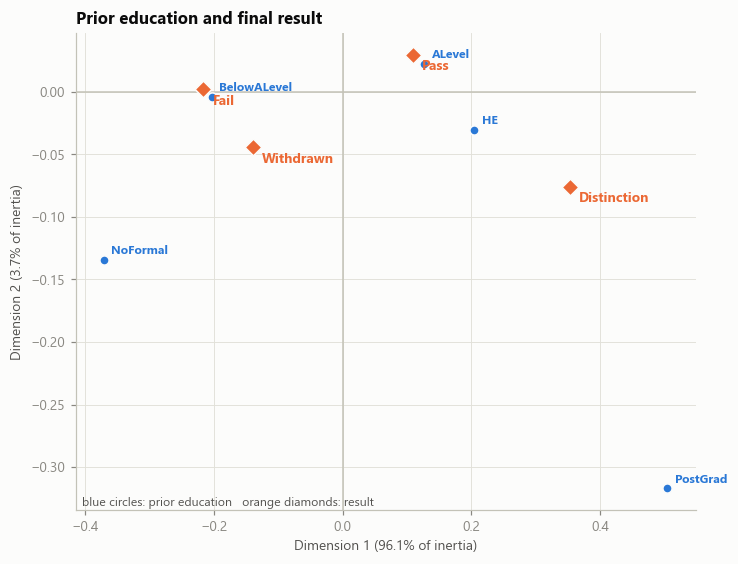

In [17]:
r_ = ca_res["Profile"]
print("Engagement profile x four results: coordinates"); display(r_["rows"][["Dim1", "Dim2"]]); display(r_["cols"][["Dim1", "Dim2"]])
ca_plot(r_, "Engagement profile and final result", "06_ca_profile_result.png", "engagement profile", "result")
r_ = ca_res["EducationFine"]
print("Prior education x four results: coordinates"); display(r_["rows"][["Dim1", "Dim2"]])
ca_plot(r_, "Prior education and final result", "06_ca_education_result.png", "prior education", "result")

**Observed.** The total inertia is 0.112 for engagement profile by result, but only 0.034 for education and 0.027 for deprivation band (chi-square 1,323, 406 and 308), so the engagement profile is about four times as strongly tied to the final result as deprivation. In all three tables the first dimension carries 91 to 96% of the inertia, so each table is essentially one ordered gradient.
- **Deprivation band by result.** The bands line up in order along dimension 1, from B01 (most deprived, -0.31) to B10 (+0.25). The results sit at Fail -0.19, Withdrawn -0.11, Pass +0.11 and Distinction +0.27: the most deprived bands are closest to Fail and Withdrawn, the least deprived to Distinction.
- **Engagement profile by result.** No activity (-0.76), low (-0.38), intermittent (-0.06) and sustained (+0.34) line up against Fail (-0.42), Withdrawn (-0.23), Pass (+0.22) and Distinction (+0.55).
- **Prior education by result.** From no formal qualification (-0.37) to postgraduate (+0.50); the second dimension (4%) mostly separates the small postgraduate group.
**Why it matters.** The maps agree with the trend tests and show *which* results sit at each end. Fail lies further out on the disadvantaged side than Withdrawn in the deprivation and engagement maps, again suggesting that "at risk" mixes two things. The second dimension explains 3 to 6% and is not interpreted.

### 4.1 Multiple correspondence analysis of the background and behaviour profile

All the categorical variables at once, with the outcome added afterwards as supplementary points (its categories did not shape the map).

Principal inertias (first 4): [0.206 0.173 0.155 0.135] | raw share: [0.11  0.092 0.082 0.072]
Benzecri-adjusted share of inertia (first 4): [0.665 0.235 0.089 0.01 ] (the raw shares understate how much the first axes explain)
scaling check passed (the centroid of 'Profile=Low' students reproduces its category coordinates)


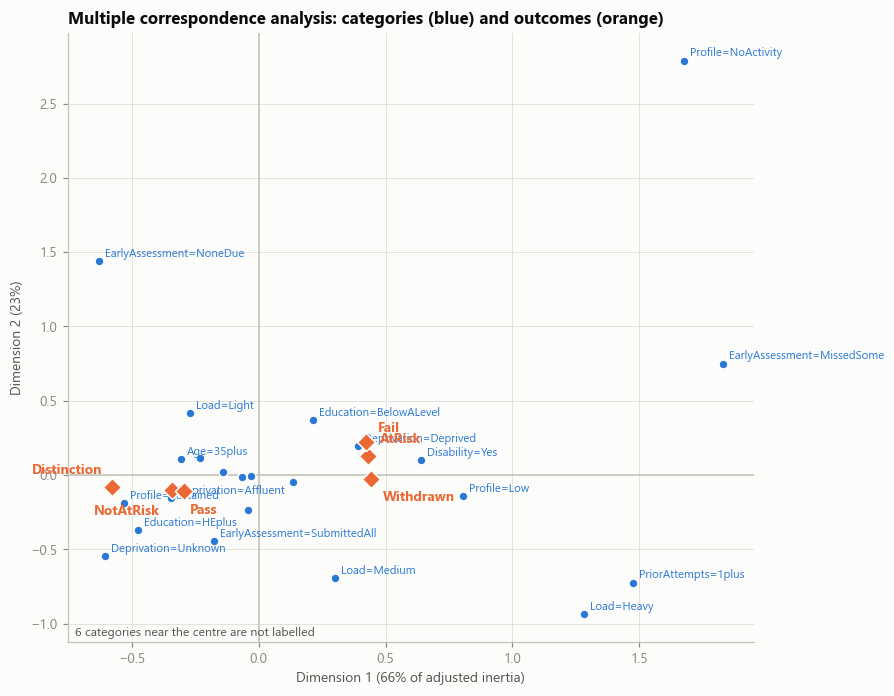

Supplementary outcome coordinates:


,Dim1,Dim2
AtRisk,0.429,0.127
NotAtRisk,-0.343,-0.102
Distinction,-0.580,-0.080
Pass,-0.296,-0.106
Fail,0.421,0.223
Withdrawn,0.442,-0.027


In [18]:
MCA_VARS = ["Profile", "Education", "Deprivation", "Age", "Disability", "PriorAttempts", "Load", "EarlyAssessment"]
Z = pd.get_dummies(cats[MCA_VARS].fillna("NA"), prefix_sep="=").astype(float)
Q = len(MCA_VARS); n_ = len(Z); P = Z.values / (n_ * Q); r = P.sum(1); c = P.sum(0)
S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
U, sv, Vt = np.linalg.svd(S, full_matrices=False)
K_ = 4
F = (U[:, :K_] / np.sqrt(r)[:, None]) * sv[:K_]; G = (Vt.T[:, :K_] / np.sqrt(c)[:, None]) * sv[:K_]
lam = sv ** 2
adj = np.where(lam > 1 / Q, (Q / (Q - 1)) ** 2 * (lam - 1 / Q) ** 2, 0.0)
print("Principal inertias (first 4):", np.round(lam[:K_], 3), "| raw share:", np.round(lam[:K_] / lam.sum(), 3))
print("Benzecri-adjusted share of inertia (first 4):", np.round(adj[:K_] / adj.sum(), 3), "(the raw shares understate how much the first axes explain)")
mca_cat = pd.DataFrame(G[:, :2], index=Z.columns, columns=["Dim1", "Dim2"])

# supplementary outcome points: centroid of the students in each outcome group, divided by the singular value (same scale as the categories)
sup = {}
for name, mask in {"AtRisk": train.target_at_risk.values == 1, "NotAtRisk": train.target_at_risk.values == 0,
                   **{rn: train.target_final_result.values == rn for rn in RESULTS}}.items():
    sup[name] = F[mask, :2].mean(axis=0) / sv[:2]
mca_sup = pd.DataFrame(sup, index=["Dim1", "Dim2"]).T
# check of the transition formula on an active category
chk = F[(Z["Profile=Low"].values == 1), :2].mean(axis=0) / sv[:2]
assert np.allclose(chk, mca_cat.loc["Profile=Low"].values, atol=1e-6), "supplementary scaling is wrong"
print("scaling check passed (the centroid of 'Profile=Low' students reproduces its category coordinates)")

fig, ax = plt.subplots(figsize=(8.2, 6.4))
ax.axhline(0, color=AXIS, linewidth=1); ax.axvline(0, color=AXIS, linewidth=1)
ax.scatter(mca_cat.Dim1, mca_cat.Dim2, color=C1, s=34, zorder=3, edgecolors=SURFACE, linewidths=1)
ax.scatter(mca_sup.Dim1, mca_sup.Dim2, color=C2, s=70, marker="D", zorder=4, edgecolors=SURFACE, linewidths=1)
far = np.hypot(mca_cat.Dim1, mca_cat.Dim2) >= 0.3          # label only categories away from the centre; the rest are close to the average profile
for lab, row in mca_cat[far].iterrows(): ax.annotate(lab, (row.Dim1, row.Dim2), xytext=(4, 3), textcoords="offset points", color=C1, fontsize=7.5)
offs = {"Distinction": (-6, 9, "right"), "Pass": (4, -15, "left"), "NotAtRisk": (-8, -16, "right"), "AtRisk": (8, 9, "left"), "Fail": (8, 7, "left"), "Withdrawn": (8, -14, "left")}
for lab, row in mca_sup.iterrows():
    dx, dy, ha = offs.get(lab, (6, -10, "left")); ax.annotate(lab, (row.Dim1, row.Dim2), xytext=(dx, dy), textcoords="offset points", color=C2, fontsize=9, fontweight="bold", ha=ha)
ax.text(0.01, 0.01, f"{int((~far).sum())} categories near the centre are not labelled", transform=ax.transAxes, fontsize=8, color=INK2)
ax.set_xlabel(f"Dimension 1 ({adj[0] / adj.sum():.0%} of adjusted inertia)"); ax.set_ylabel(f"Dimension 2 ({adj[1] / adj.sum():.0%})")
ax.set_title("Multiple correspondence analysis: categories (blue) and outcomes (orange)")
fig.tight_layout(); savefig(fig, "06_mca_map.png"); plt.show()
print("Supplementary outcome coordinates:"); display(mca_sup)

**Observed.** The first two axes carry 66% and 23% of the adjusted inertia (the unadjusted shares, 11% and 9%, understate this, as is usual for indicator-matrix MCA). Dimension 1 is a **disadvantage and disengagement axis**: on its positive side are missed early assessments (+1.8), previous attempts (+1.5), heavy load (+1.3), low engagement (+0.8), disability (+0.6) and high deprivation (+0.4); on its negative side are sustained engagement, higher education and affluent areas. The outcomes added afterwards line up the same way: at risk (+0.43), Fail (+0.42) and Withdrawn (+0.44) on the positive side, Distinction (-0.58), not at risk (-0.34) and Pass (-0.30) on the negative side. Dimension 2 separates the special cases of students with no activity (+2.8) or no assessment due (+1.4).
**Why it matters.** The whole set of categorical variables reduces to one dominant gradient that the final result follows, which is consistent with the continuum found in notebook 05.
**Caution.** Rare categories (no activity, missed assessment) sit far from the centre because they are rare, not necessarily because they matter most; read the map together with the rule table.

## 5. Save outputs

In [19]:
keep = R[(R.q < 0.05) & (R.improvement >= IMPROVE) & (R.n_antecedent >= 150) & (R.lift >= 1.25)].copy()
keep["antecedent_items"] = keep.antecedents.apply(lambda s: "|".join(sorted(s)))
keep[["rule", "antecedent_items", "consequent", "n_antecedent", "support", "confidence", "conf_lo", "conf_hi", "lift", "recall", "q", "improvement", "len"]] \
    .sort_values(["consequent", "lift"], ascending=[True, False]).to_csv(OUT / "association_rules_2013.csv", index=False)
trend.to_csv(OUT / "trend_tests.csv"); cmh.to_csv(OUT / "cmh_tests.csv")
pd.concat([ca_res["IMDBand"]["rows"].assign(table="imd_band"), ca_res["Profile"]["rows"].assign(table="profile"), ca_res["EducationFine"]["rows"].assign(table="education")]).to_csv(OUT / "ca_row_coordinates.csv")
pd.concat([mca_cat.assign(kind="category"), mca_sup.assign(kind="outcome")]).to_csv(OUT / "mca_coordinates.csv")
(OUT / "item_spec.json").write_text(json.dumps({"spec": spec, "min_support": MIN_SUP, "max_len": MAX_LEN, "improvement": IMPROVE, "min_antecedent_n": 150, "min_lift": 1.25,
                                                 "support_list_rules_precision_70": chosen70, "support_list_rules_precision_60": chosen}, indent=2))
print(f"saved {len(keep):,} significant, non-redundant rules to association_rules_2013.csv")
keep.consequent.value_counts().to_frame("rules")

saved 173 significant, non-redundant rules to association_rules_2013.csv


,rules
consequent,
Outcome=NotAtRisk,59
Outcome=AtRisk,50
Result=Fail,24
Result=Pass,20
Result=Withdrawn,12
Result=Distinction,8


## 6. Synthesis

**What goes with being at risk (RQ1).** One behavioural fact dominates: not handing in an assessment that was due in the first four weeks (87.6% at risk, 12.4% of students). Engagement profile and early score follow (Cramer's V about 0.3). A disadvantaged background (low prior education, deprivation, previous attempts, disability) adds a few points on top of behaviour, and combinations of a missed assessment with a disadvantaged background reach 91 to 96% confidence for small groups. Gender plays no role.

**Where the equity gaps are (RQ4).** The deprivation and education gradients are not module artefacts (Mantel-Haenszel odds ratios match the crude ones and are the same in every module). They are largest (13 to 16 points) for students who look fine on the platform and shrink to 5 points once an assessment has been missed, so alerts based on behaviour alone would miss disadvantaged students who still attend.

**What the methods showed.** Correspondence analysis reduces each table to a single ordered gradient (91 to 96% of inertia); engagement is about four times as strongly tied to the result as deprivation. The engagement effect differs a lot between modules (odds ratio 11.7 in EEE, 1.6 in GGG), so pooled statements about engagement should be qualified.

**Limits.**
- Everything is association on the 2013 years; the rules are not validated yet.
- With this sample size significance is not selective, so effect sizes, intervals and the improvement filter carry the weight.
- Rule lists trade precision for reach: reaching most at-risk students means contacting about half of the cohort.
- Items depend on cut points (tertiles, 7 days, merged education and age levels); these were fixed before looking at the outcome and are documented.

**Carried forward**

| Notebook | Use |
|---|---|
| 07 modelling, drift and fairness | Replicate the 173 saved rules and the profile risks on 2014 once (confidence, lift, rank stability); compare the rule lists with the model; test a module interaction for engagement; report group-wise errors for deprived and low-education students |